In [117]:
import sys
from pathlib import Path

# Add parent directory to path so forestgap can be imported
sys.path.insert(0, str(Path('.').resolve().parent))

In [118]:
from forestgap import SparseProximityMixin, with_sparse_proximity, _RotationForestApplyAdapter
from aeon.classification.sklearn import RotationForestClassifier
from aeon.regression.sklearn import RotationForestRegressor

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.manifold import MDS
from phate import PHATE

In [119]:
data_name = 'iris'

data = pd.read_csv("..\datasets\\" + data_name + ".csv")

y = data.iloc[:, 0]
X = data.iloc[:, 1:]

In [120]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

train_order = np.argsort(y_train.to_numpy())
test_order = np.argsort(y_test.to_numpy())

X_train = X_train.iloc[train_order].reset_index(drop=True)
y_train = y_train.iloc[train_order].reset_index(drop=True)

X_test = X_test.iloc[test_order].reset_index(drop=True)
y_test = y_test.iloc[test_order].reset_index(drop=True)

In [121]:
rf_class = with_sparse_proximity(RotationForestClassifier)
# rf_class = with_sparse_proximity(RandomForestClassifier)
rf = rf_class(n_estimators = 100, random_state = 0, prox_method = 'rfgap')

In [122]:
rf.fit(X_train, y_train)
score = rf.score(X_test, y_test)
print('Score: ', score)

c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Score:  0.9777777777777777


c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


In [123]:
rf.apply(X_train)

array([[ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       ...,
       [ 8, 12, 14, ..., 10, 10, 10],
       [ 8, 12, 14, ..., 10, 10, 10],
       [ 8, 10, 14, ...,  5, 10, 10]], dtype=int64)

In [124]:
prox = rf.get_proximities().toarray()
prox_symmetric = prox + prox.T - np.diag(prox.diagonal())

prox_scaled = (prox_symmetric - prox_symmetric.min()) / (prox_symmetric.max() - prox_symmetric.min())

In [ ]:
mds = MDS(n_components = 2, dissimilarity = 'precomputed', random_state = 0)
emb = mds.fit_transform(1 - prox_scaled)

# phate_op = PHATE(n_components= 2, knn_dist = 'precomputed_affinity')
# emb = phate_op.fit_transform(prox_scaled)

<Axes: >

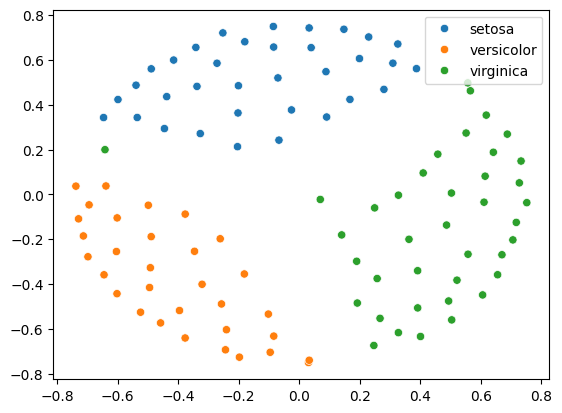

In [130]:
sns.scatterplot(x = emb[:, 0], y = emb[:, 1], hue = pd.Categorical(y_train.iloc[:]))

<Axes: >

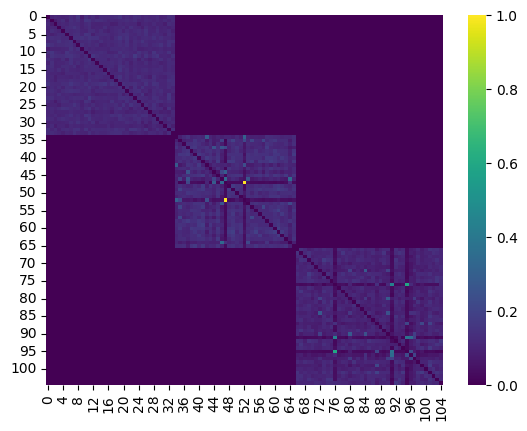

In [129]:
sns.heatmap(prox_scaled, cmap='viridis')